<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Volitility_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================================
# PART 1 : DATA COLLECTION
# ==========================================================

!pip install -q yfinance ta arch

# ----------------------------------------------------------
# Imports
# ----------------------------------------------------------

import yfinance as yf
import pandas as pd
import numpy as np

# ----------------------------------------------------------
# Download NIFTY 50
# ----------------------------------------------------------

ticker = "^NSEI"

df = yf.download(

    ticker,

    start="2015-01-01",

    end="2026-01-01",

    auto_adjust=True,

    progress=False

)

# ----------------------------------------------------------
# Fix MultiIndex (Latest yfinance)
# ----------------------------------------------------------

if isinstance(df.columns, pd.MultiIndex):

    df.columns = df.columns.get_level_values(0)

# ----------------------------------------------------------
# Reset Index
# ----------------------------------------------------------

df.reset_index(inplace=True)

# ----------------------------------------------------------
# Convert to Series
# ----------------------------------------------------------

for col in [

    "Open",

    "High",

    "Low",

    "Close",

    "Volume"

]:

    df[col] = df[col].squeeze()

# ----------------------------------------------------------
# Dataset Information
# ----------------------------------------------------------

print("="*60)

print("NIFTY 50 DATASET")

print("="*60)

print("Shape :", df.shape)

print("\nColumns")

print(df.columns.tolist())

print("\nData Types")

print(df.dtypes)

print("\nMissing Values")

print(df.isnull().sum())

print("\nFirst Five Rows")

print(df.head())

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 17.0 MB/s eta 0:00:00
NIFTY 50 DATASET
Shape : (2708, 6)

Columns
['Date', 'Close', 'High', 'Low', 'Open', 'Volume']

Data Types
Price
Date      datetime64[ns]
Close            float64
High             float64
Low              float64
Open             float64
Volume             int64
dtype: object

Missing Values
Price
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

First Five Rows
Price       Date        Close         High          Low         Open  Volume
0     2015-01-02  8395.450195  8410.599609  8288.700195  8288.700195  101900
1     2015-01-05  8378.400391  8445.599609  8363.900391  8407.950195  118200
2     2015-01-06  8127.350098  8327.849609  8111.350098  8325.299805  172800
3     2015-01-07  8102.100098  8151.200195  8065.450195  8118.649902  164100
4     2015-01-08  8234.599609  8243.500000  8167.299805  8191.399902  143800


In [ ]:
# ==========================================================
# PART 2 : FEATURE ENGINEERING
# ==========================================================

import ta

# ----------------------------------------------------------
# Log Returns
# ----------------------------------------------------------

df["Log_Return"] = np.log(
    df["Close"] / df["Close"].shift(1)
)

# ----------------------------------------------------------
# Daily Returns
# ----------------------------------------------------------

df["Return"] = df["Close"].pct_change()

# ----------------------------------------------------------
# Annualized Historical Volatility (20-Day)
# ----------------------------------------------------------

window = 20

df["Volatility"] = (

    df["Log_Return"]

    .rolling(window)

    .std()

    * np.sqrt(252)

)

# ----------------------------------------------------------
# RSI
# ----------------------------------------------------------

df["RSI"] = ta.momentum.RSIIndicator(

    close=df["Close"],

    window=14

).rsi()

# ----------------------------------------------------------
# MACD
# ----------------------------------------------------------

macd = ta.trend.MACD(

    close=df["Close"]

)

df["MACD"] = macd.macd()

df["MACD_SIGNAL"] = macd.macd_signal()

df["MACD_HIST"] = macd.macd_diff()

# ----------------------------------------------------------
# ATR
# ----------------------------------------------------------

atr = ta.volatility.AverageTrueRange(

    high=df["High"],

    low=df["Low"],

    close=df["Close"]

)

df["ATR"] = atr.average_true_range()

# ----------------------------------------------------------
# Bollinger Band Width
# ----------------------------------------------------------

bb = ta.volatility.BollingerBands(

    close=df["Close"],

    window=20

)

df["BB_WIDTH"] = (

    bb.bollinger_hband()

    -

    bb.bollinger_lband()

)

# ----------------------------------------------------------
# ADX
# ----------------------------------------------------------

adx = ta.trend.ADXIndicator(

    high=df["High"],

    low=df["Low"],

    close=df["Close"]

)

df["ADX"] = adx.adx()

# ----------------------------------------------------------
# ROC
# ----------------------------------------------------------

df["ROC"] = ta.momentum.ROCIndicator(

    close=df["Close"]

).roc()

# ----------------------------------------------------------
# Volume Change
# ----------------------------------------------------------

df["Volume_Change"] = (

    df["Volume"]

    .pct_change()

)

# ----------------------------------------------------------
# Momentum
# ----------------------------------------------------------

df["Momentum"] = (

    df["Close"]

    -

    df["Close"].shift(10)

)

# ----------------------------------------------------------
# Clean Dataset
# ----------------------------------------------------------

df.replace(

    [np.inf, -np.inf],

    np.nan,

    inplace=True

)

df.dropna(inplace=True)

df.reset_index(drop=True, inplace=True)

# ----------------------------------------------------------
# Feature Matrix
# ----------------------------------------------------------

features = [

    "Open",

    "High",

    "Low",

    "Close",

    "Volume",

    "RSI",

    "MACD",

    "MACD_SIGNAL",

    "MACD_HIST",

    "ATR",

    "BB_WIDTH",

    "ADX",

    "ROC",

    "Volume_Change",

    "Momentum"

]

X = df[features]

y = df["Volatility"]

print("="*60)

print("FEATURE ENGINEERING COMPLETED")

print("="*60)

print("Feature Shape :", X.shape)

print("Target Shape :", y.shape)

print("\nTarget Statistics")

print(y.describe())

print("\nFirst Five Rows")

print(df[["Date","Close","Volatility"]].head())

FEATURE ENGINEERING COMPLETED
Feature Shape : (2614, 15)
Target Shape : (2614,)

Target Statistics
count    2614.000000
mean        0.140825
std         0.083613
min         0.050175
25%         0.095986
50%         0.121454
75%         0.158485
max         0.904851
Name: Volatility, dtype: float64

First Five Rows
Price       Date        Close  Volatility
0     2015-04-13  8834.000000    0.145233
1     2015-04-16  8706.700195    0.144951
2     2015-04-17  8606.000000    0.150970
3     2015-04-20  8448.099609    0.158852
4     2015-04-21  8377.750000    0.160414


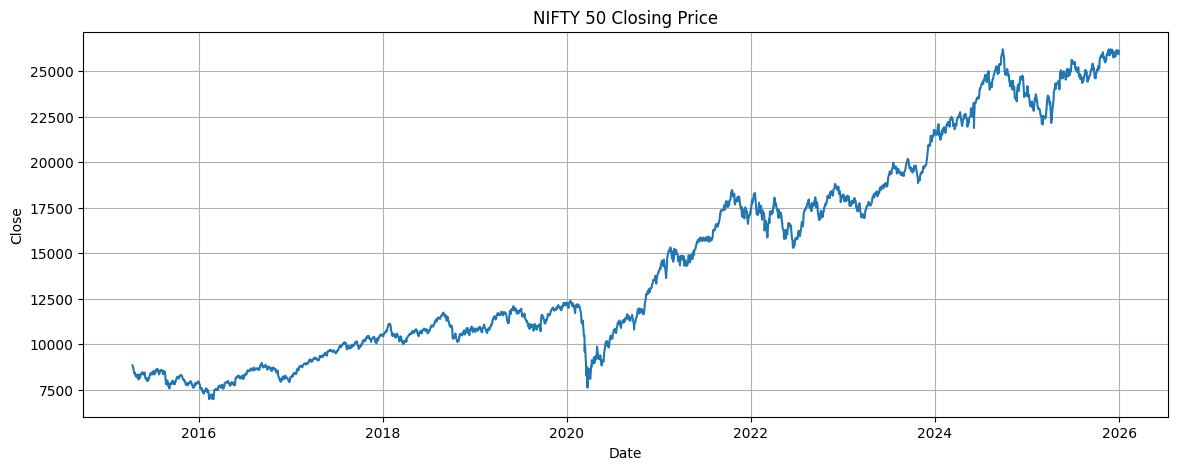

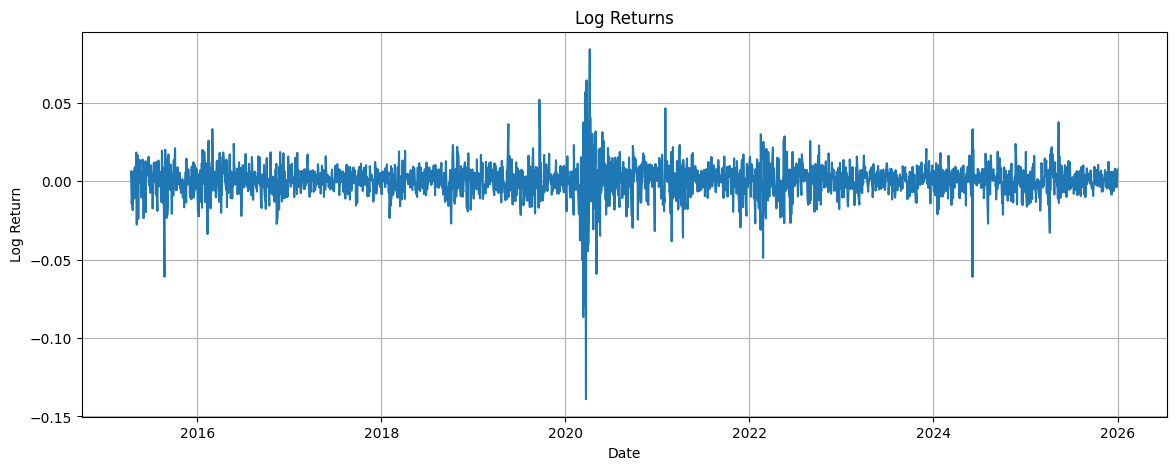

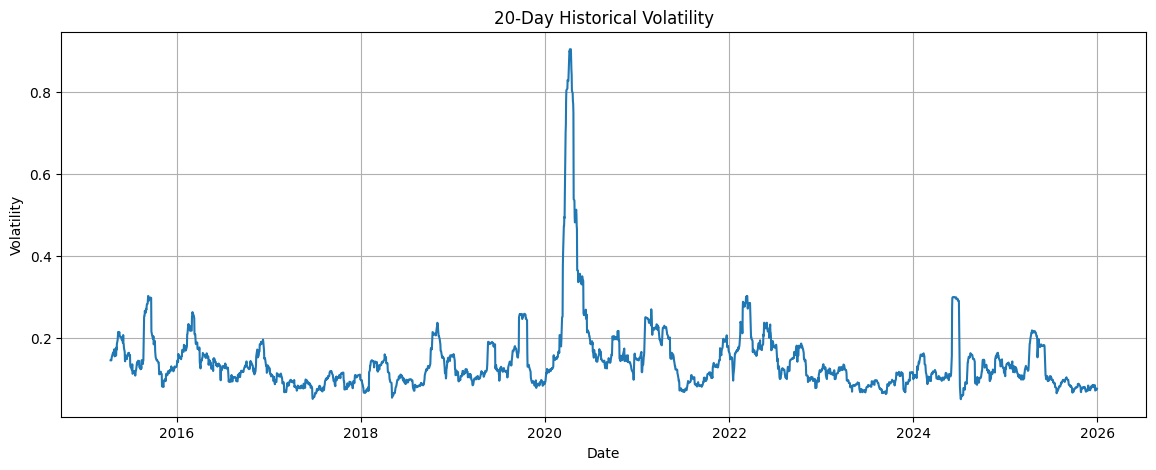

In [ ]:
# ==========================================================
# PART 3 : EXPLORATORY DATA ANALYSIS
# ==========================================================

import matplotlib.pyplot as plt

# ----------------------------------------------------------
# Plot 1 : Closing Price
# ----------------------------------------------------------

plt.figure(figsize=(14,5))

plt.plot(df["Date"], df["Close"])

plt.title("NIFTY 50 Closing Price")

plt.xlabel("Date")

plt.ylabel("Close")

plt.grid(True)

plt.show()

# ----------------------------------------------------------
# Plot 2 : Log Returns
# ----------------------------------------------------------

plt.figure(figsize=(14,5))

plt.plot(df["Date"], df["Log_Return"])

plt.title("Log Returns")

plt.xlabel("Date")

plt.ylabel("Log Return")

plt.grid(True)

plt.show()

# ----------------------------------------------------------
# Plot 3 : Historical Volatility
# ----------------------------------------------------------

plt.figure(figsize=(14,5))

plt.plot(df["Date"], df["Volatility"])

plt.title("20-Day Historical Volatility")

plt.xlabel("Date")

plt.ylabel("Volatility")

plt.grid(True)

plt.show()

In [ ]:
# ==========================================================
# SUMMARY STATISTICS
# ==========================================================

print("="*60)

print("SUMMARY STATISTICS")

print("="*60)

print(df[

    [

        "Return",

        "Log_Return",

        "Volatility"

    ]

].describe())

SUMMARY STATISTICS
Price       Return   Log_Return   Volatility
count  2614.000000  2614.000000  2614.000000
mean      0.000460     0.000406     0.140825
std       0.010277     0.010339     0.083613
min      -0.129805    -0.139038     0.050175
25%      -0.004281    -0.004291     0.095986
50%       0.000596     0.000596     0.121454
75%       0.005855     0.005838     0.158485
max       0.087632     0.084003     0.904851


In [ ]:
# ==========================================================
# PART 4 : ROLLING GARCH FORECAST
# ==========================================================

from arch import arch_model
import numpy as np

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ----------------------------------------------------------
# Prepare Returns
# ----------------------------------------------------------

returns = df["Log_Return"] * 100

# ----------------------------------------------------------
# Train-Test Split
# ----------------------------------------------------------

split = int(len(returns) * 0.80)

train_returns = returns.iloc[:split]

test_returns = returns.iloc[split:]

actual_vol = y.iloc[split:].reset_index(drop=True)

# ----------------------------------------------------------
# Rolling Forecast
# ----------------------------------------------------------

history = train_returns.copy()

garch_predictions = []

for i in range(len(test_returns)):

    model = arch_model(

        history,

        vol="GARCH",

        p=1,

        q=1,

        mean="Zero"

    )

    model_fit = model.fit(

        disp="off"

    )

    forecast = model_fit.forecast(

        horizon=1

    )

    predicted_vol = np.sqrt(

        forecast.variance.iloc[-1,0]

    ) / 100

    garch_predictions.append(

        predicted_vol

    )

    history = np.append(

        history,

        test_returns.iloc[i]

    )

# ----------------------------------------------------------
# Convert to Array
# ----------------------------------------------------------

garch_predictions = np.array(

    garch_predictions

)

# ----------------------------------------------------------
# Match Length
# ----------------------------------------------------------

n = min(

    len(actual_vol),

    len(garch_predictions)

)

actual_vol = actual_vol.iloc[:n]

garch_predictions = garch_predictions[:n]

# ----------------------------------------------------------
# Metrics
# ----------------------------------------------------------

garch_rmse = np.sqrt(

    mean_squared_error(

        actual_vol,

        garch_predictions

    )

)

garch_mae = mean_absolute_error(

    actual_vol,

    garch_predictions

)

garch_r2 = r2_score(

    actual_vol,

    garch_predictions

)

garch_mape = np.mean(

    np.abs(

        (actual_vol-garch_predictions)

        / actual_vol

    )

) * 100

print("="*60)

print("ROLLING GARCH RESULTS")

print("="*60)

print(f"RMSE : {garch_rmse:.6f}")

print(f"MAE  : {garch_mae:.6f}")

print(f"R²   : {garch_r2:.4f}")

print(f"MAPE : {garch_mape:.2f}%")

ROLLING GARCH RESULTS
RMSE : 0.121115
MAE  : 0.112128
R²   : -5.4068
MAPE : 92.81%


In [ ]:
# ==========================================================
# PART 5 : TRANSFORMER DATA PREPARATION
# ==========================================================

from sklearn.preprocessing import StandardScaler
import numpy as np

# ----------------------------------------------------------
# Feature Scaling
# ----------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# ----------------------------------------------------------
# Predict 5-Day Ahead Volatility
# ----------------------------------------------------------

prediction_horizon = 5

future_volatility = df["Volatility"].shift(-prediction_horizon)

# ----------------------------------------------------------
# Remove Missing Target
# ----------------------------------------------------------

valid = future_volatility.notna()

X_scaled = X_scaled[valid]

future_volatility = future_volatility[valid].reset_index(drop=True)

# ----------------------------------------------------------
# Sequence Generation
# ----------------------------------------------------------

sequence_length = 30

X_seq = []
y_seq = []

for i in range(sequence_length, len(X_scaled)):

    X_seq.append(
        X_scaled[i-sequence_length:i]
    )

    y_seq.append(
        future_volatility.iloc[i]
    )

X_seq = np.array(X_seq)
y_seq = np.array(y_seq)

# ----------------------------------------------------------
# Train-Test Split
# ----------------------------------------------------------

split = int(len(X_seq) * 0.80)

X_train = X_seq[:split]
X_test = X_seq[split:]

y_train = y_seq[:split]
y_test = y_seq[split:]

# ----------------------------------------------------------
# Check Shapes
# ----------------------------------------------------------

print("="*60)

print("TRANSFORMER DATASET")

print("="*60)

print("Sequence Shape :", X_seq.shape)

print("Training Shape :", X_train.shape)

print("Testing Shape  :", X_test.shape)

print("Target Shape   :", y_seq.shape)

print("Features       :", X_train.shape[2])

print("Sequence Length:", X_train.shape[1])

TRANSFORMER DATASET
Sequence Shape : (2579, 30, 15)
Training Shape : (2063, 30, 15)
Testing Shape  : (516, 30, 15)
Target Shape   : (2579,)
Features       : 15
Sequence Length: 30


In [ ]:
# ==========================================================
# PART 6 : TRANSFORMER MODEL
# ==========================================================

import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D
)

from tensorflow.keras.models import Model

# ----------------------------------------------------------
# Input Layer
# ----------------------------------------------------------

inputs = Input(
    shape=(X_train.shape[1], X_train.shape[2])
)

# ----------------------------------------------------------
# Transformer Encoder Block 1
# ----------------------------------------------------------

attention1 = MultiHeadAttention(
    num_heads=4,
    key_dim=16
)(inputs, inputs)

x = LayerNormalization()(inputs + attention1)

ffn1 = Dense(
    128,
    activation="relu"
)(x)

ffn1 = Dense(
    X_train.shape[2]
)(ffn1)

x = LayerNormalization()(x + ffn1)

# ----------------------------------------------------------
# Transformer Encoder Block 2
# ----------------------------------------------------------

attention2 = MultiHeadAttention(
    num_heads=4,
    key_dim=16
)(x, x)

x2 = LayerNormalization()(x + attention2)

ffn2 = Dense(
    128,
    activation="relu"
)(x2)

ffn2 = Dense(
    X_train.shape[2]
)(ffn2)

x = LayerNormalization()(x2 + ffn2)

# ----------------------------------------------------------
# Global Pooling
# ----------------------------------------------------------

x = GlobalAveragePooling1D()(x)

# ----------------------------------------------------------
# Dense Layers
# ----------------------------------------------------------

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.30)(x)

x = Dense(
    32,
    activation="relu"
)(x)

# ----------------------------------------------------------
# Output Layer
# ----------------------------------------------------------

outputs = Dense(
    1,
    activation="linear"
)(x)

# ----------------------------------------------------------
# Build Model
# ----------------------------------------------------------

model = Model(
    inputs,
    outputs
)

# ----------------------------------------------------------
# Compile
# ----------------------------------------------------------

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="mse",

    metrics=["mae"]

)

# ----------------------------------------------------------
# Summary
# ----------------------------------------------------------

model.summary()

Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_12      │ (None, 30, 15)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 15)    │      4,047 │ input_layer_12[0… │
│ (MultiHeadAttentio… │                   │            │ input_layer_12[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_24 (Add)        │ (None, 30, 15)    │          0 │ input_layer_12[0… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 15)    │         30 │ add_24[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_37 (Dense)    │ (None, 30, 128)   │      2,048 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_38 (Dense)    │ (None, 30, 15)    │      1,935 │ dense_37[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_25 (Add)        │ (None, 30, 15)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_38[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 15)    │         30 │ add_25[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 15)    │      4,047 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_26 (Add)        │ (None, 30, 15)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 15)    │         30 │ add_26[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_39 (Dense)    │ (None, 30, 128)   │      2,048 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_40 (Dense)    │ (None, 30, 15)    │      1,935 │ dense_39[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_27 (Add)        │ (None, 30, 15)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_40[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 15)    │         30 │ add_27[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 15)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_41 (Dense)    │ (None, 64)        │      1,024 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_26          │ (None, 64)        │          0 │ dense_41[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 19,317 (75.46 KB)

 Trainable params: 19,317 (75.46 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==========================================================
# PART 7 : OPTUNA HYPERPARAMETER OPTIMIZATION
# ==========================================================

!pip install -q optuna

import optuna
import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D
)

from tensorflow.keras.models import Model

# ----------------------------------------------------------
# Objective Function
# ----------------------------------------------------------

def objective(trial):

    num_heads = trial.suggest_categorical(
        "num_heads",
        [2,4,8]
    )

    key_dim = trial.suggest_categorical(
        "key_dim",
        [8,16,32]
    )

    ff_units = trial.suggest_categorical(
        "ff_units",
        [64,128,256]
    )

    dropout = trial.suggest_float(
        "dropout",
        0.20,
        0.50
    )

    learning_rate = trial.suggest_float(
        "learning_rate",
        1e-4,
        1e-2,
        log=True
    )

    batch_size = trial.suggest_categorical(
        "batch_size",
        [32,64,128]
    )

    # -----------------------------
    # Model
    # -----------------------------

    inputs = Input(
        shape=(X_train.shape[1], X_train.shape[2])
    )

    attention = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim
    )(inputs, inputs)

    x = LayerNormalization()(inputs + attention)

    ffn = Dense(
        ff_units,
        activation="relu"
    )(x)

    ffn = Dense(
        X_train.shape[2]
    )(ffn)

    x = LayerNormalization()(x + ffn)

    x = GlobalAveragePooling1D()(x)

    x = Dropout(dropout)(x)

    x = Dense(
        64,
        activation="relu"
    )(x)

    outputs = Dense(
        1,
        activation="linear"
    )(x)

    model = Model(
        inputs,
        outputs
    )

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),

        loss="mse",

        metrics=["mae"]

    )

    history = model.fit(

        X_train,

        y_train,

        validation_split=0.20,

        epochs=10,

        batch_size=batch_size,

        verbose=0

    )

    return min(history.history["val_loss"])

# ----------------------------------------------------------
# Run Optuna
# ----------------------------------------------------------

study = optuna.create_study(
    direction="minimize"
)

study.optimize(
    objective,
    n_trials=10
)

print("="*60)

print("BEST PARAMETERS")

print("="*60)

print(study.best_params)

print("\nBest Validation Loss")

print(study.best_value)

[I 2026-08-02 10:11:11,670] A new study created in memory with name: no-name-b97d3e99-fce4-45a6-8495-e9030fe16e0f
[I 2026-08-02 10:11:25,630] Trial 0 finished with value: 0.01622108183801174 and parameters: {'num_heads': 2, 'key_dim': 8, 'ff_units': 128, 'dropout': 0.23553175112952407, 'learning_rate': 0.0001855751782319528, 'batch_size': 32}. Best is trial 0 with value: 0.01622108183801174.
[I 2026-08-02 10:11:39,462] Trial 1 finished with value: 0.002312939614057541 and parameters: {'num_heads': 2, 'key_dim': 16, 'ff_units': 64, 'dropout': 0.29158983106975467, 'learning_rate': 0.0008627537794699453, 'batch_size': 32}. Best is trial 1 with value: 0.002312939614057541.
[I 2026-08-02 10:11:53,836] Trial 2 finished with value: 0.006213003303855658 and parameters: {'num_heads': 4, 'key_dim': 8, 'ff_units': 128, 'dropout': 0.2869223353707854, 'learning_rate': 0.0015750546921609598, 'batch_size': 64}. Best is trial 1 with value: 0.002312939614057541.
[I 2026-08-02 10:12:07,624] Trial 3 fini

BEST PARAMETERS
{'num_heads': 4, 'key_dim': 32, 'ff_units': 256, 'dropout': 0.3839287062933622, 'learning_rate': 0.009378252752745878, 'batch_size': 64}

Best Validation Loss
0.0012729245936498046


In [ ]:

# ==========================================================
# PART 8 : FINAL TRAINING
# ==========================================================

import tensorflow as tf
import numpy as np

from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import *

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ----------------------------------------------------------
# Best Parameters
# ----------------------------------------------------------

params = study.best_params

# ----------------------------------------------------------
# Build Final Transformer
# ----------------------------------------------------------

inputs = Input(
    shape=(X_train.shape[1], X_train.shape[2])
)

# Encoder Block 1

attention = MultiHeadAttention(

    num_heads=params["num_heads"],

    key_dim=params["key_dim"]

)(inputs, inputs)

x = LayerNormalization()(inputs + attention)

ffn = Dense(

    params["ff_units"],

    activation="relu"

)(x)

ffn = Dense(

    X_train.shape[2]

)(ffn)

x = LayerNormalization()(x + ffn)

# Encoder Block 2

attention = MultiHeadAttention(

    num_heads=params["num_heads"],

    key_dim=params["key_dim"]

)(x, x)

x2 = LayerNormalization()(x + attention)

ffn = Dense(

    params["ff_units"],

    activation="relu"

)(x2)

ffn = Dense(

    X_train.shape[2]

)(ffn)

x = LayerNormalization()(x2 + ffn)

# Pooling

x = GlobalAveragePooling1D()(x)

x = Dropout(params["dropout"])(x)

x = Dense(

    64,

    activation="relu"

)(x)

x = Dense(

    32,

    activation="relu"

)(x)

outputs = Dense(1)(x)

model = Model(inputs, outputs)

model.compile(

    optimizer=tf.keras.optimizers.Adam(

        learning_rate=params["learning_rate"]

    ),

    loss="mse",

    metrics=["mae"]

)

# ----------------------------------------------------------
# Callbacks
# ----------------------------------------------------------

callbacks = [

    EarlyStopping(

        monitor="val_loss",

        patience=5,

        restore_best_weights=True

    ),

    ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=3,

        min_lr=1e-6

    )

]

# ----------------------------------------------------------
# Train
# ----------------------------------------------------------

history = model.fit(

    X_train,

    y_train,

    validation_split=0.20,

    epochs=40,

    batch_size=params["batch_size"],

    callbacks=callbacks,

    verbose=1

)

# ----------------------------------------------------------
# Prediction
# ----------------------------------------------------------

pred = model.predict(X_test).flatten()

# ----------------------------------------------------------
# Transformer Metrics
# ----------------------------------------------------------

transformer_rmse = np.sqrt(

    mean_squared_error(

        y_test,

        pred

    )

)

transformer_mae = mean_absolute_error(

    y_test,

    pred

)

transformer_r2 = r2_score(

    y_test,

    pred

)

transformer_mape = np.mean(

    np.abs(

        (y_test-pred)

        / y_test

    )

)*100

print("="*60)

print("TRANSFORMER RESULTS")

print("="*60)

print(f"RMSE : {transformer_rmse:.6f}")

print(f"MAE  : {transformer_mae:.6f}")

print(f"R²   : {transformer_r2:.4f}")

print(f"MAPE : {transformer_mape:.2f}%")

Epoch 1/40
26/26 ━━━━━━━━━━━━━━━━━━━━ 18s 276ms/step - loss: 0.0610 - mae: 0.1630 - val_loss: 0.0073 - val_mae: 0.0661 - learning_rate: 0.0094
Epoch 2/40
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0089 - mae: 0.0576 - val_loss: 0.0066 - val_mae: 0.0642 - learning_rate: 0.0094
Epoch 3/40
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0067 - mae: 0.0503 - val_loss: 0.0041 - val_mae: 0.0473 - learning_rate: 0.0094
Epoch 4/40
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0051 - mae: 0.0477 - val_loss: 0.0048 - val_mae: 0.0399 - learning_rate: 0.0094
Epoch 5/40
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0040 - mae: 0.0424 - val_loss: 0.0015 - val_mae: 0.0331 - learning_rate: 0.0094
Epoch 6/40
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0028 - mae: 0.0366 - val_loss: 0.0027 - val_mae: 0.0429 - learning_rate: 0.0094
Epoch 7/40
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0027 - mae: 0.0361 - val_loss: 0.0017 - val_mae: 0.0310 - learning_rate: 0.0094
Epoch 8/40
26/26

In [ ]:
# ==========================================================
# PART 9 : GARCH vs TRANSFORMER
# ==========================================================

comparison = pd.DataFrame({

    "Model":[

        "Rolling GARCH",

        "Transformer"

    ],

    "RMSE":[

        garch_rmse,

        transformer_rmse

    ],

    "MAE":[

        garch_mae,

        transformer_mae

    ],

    "R²":[

        garch_r2,

        transformer_r2

    ],

    "MAPE":[

        garch_mape,

        transformer_mape

    ]

})

print("="*70)

print("MODEL COMPARISON")

print("="*70)

print(comparison)

MODEL COMPARISON
           Model      RMSE       MAE        R²       MAPE
0  Rolling GARCH  0.121115  0.112128 -5.406821  92.813697
1    Transformer  0.046674  0.029418  0.060855  23.057193


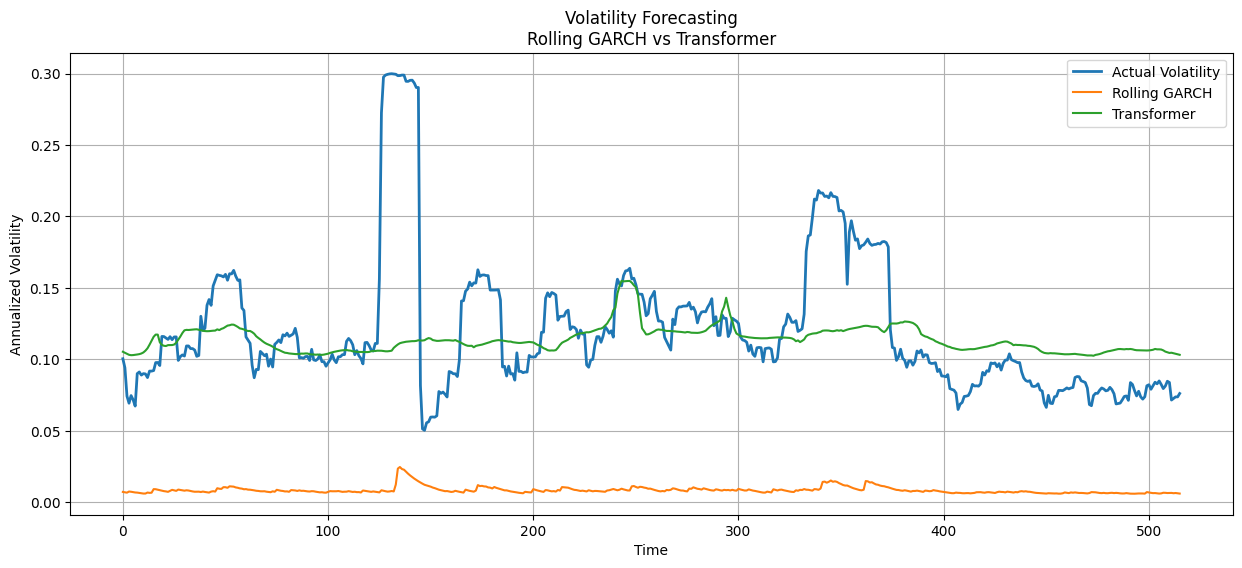

In [ ]:
# ==========================================================
# PART 10 : VISUALIZATION
# ==========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(15,6))

plt.plot(

    y_test,

    label="Actual Volatility",

    linewidth=2

)

plt.plot(

    garch_predictions[:len(y_test)],

    label="Rolling GARCH"

)

plt.plot(

    pred,

    label="Transformer"

)

plt.title(

    "Volatility Forecasting\nRolling GARCH vs Transformer"

)

plt.xlabel("Time")

plt.ylabel("Annualized Volatility")

plt.legend()

plt.grid(True)

plt.show()